<a href="https://colab.research.google.com/github/FebryanAkt/Pembelajaran-Mesin-2026/blob/main/T9_244107020180_Febryan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1

In [2]:
	# Load data
	import pandas as pd
	data = pd.read_csv('iris.csv')
	data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
	data.info()
	data.describe()
	data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


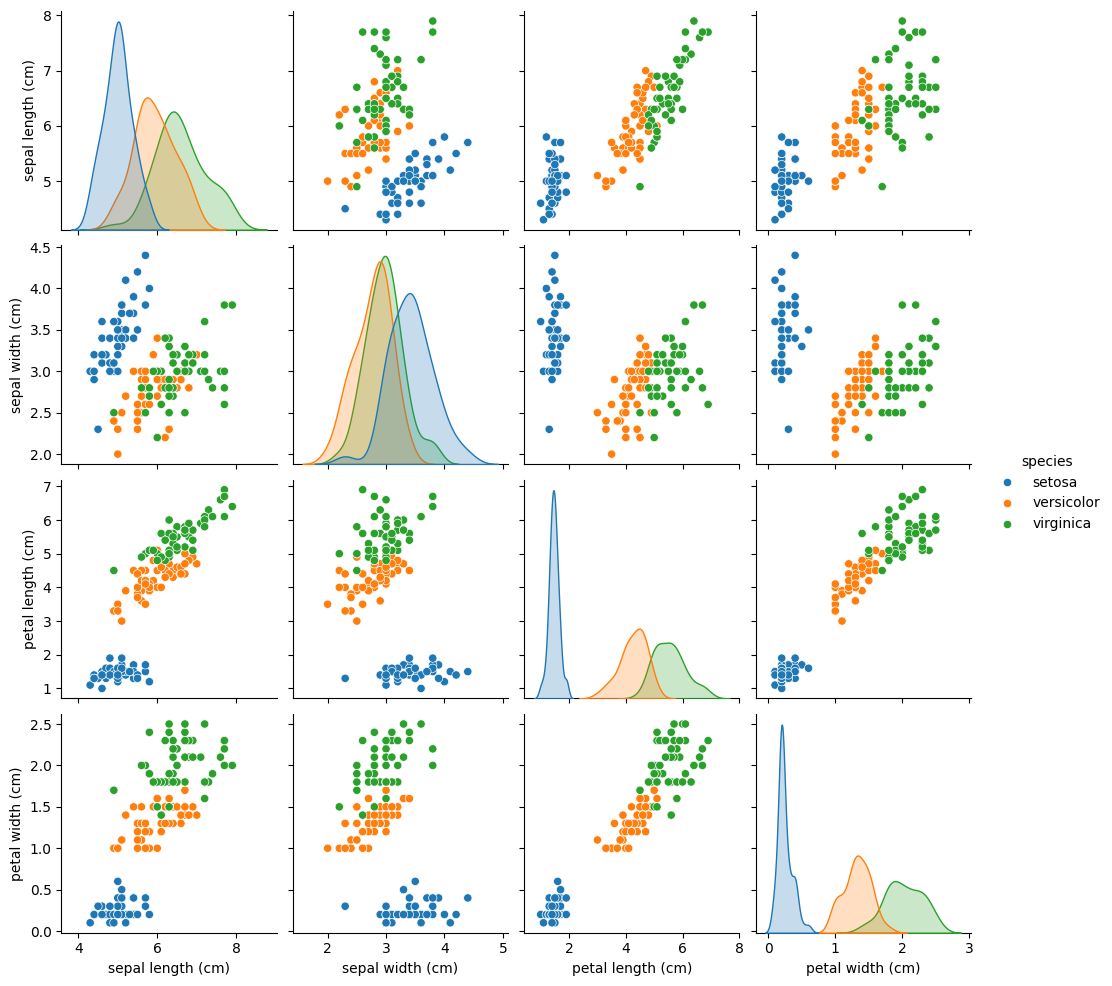

In [4]:
	import seaborn as sns
	import matplotlib.pyplot as plt

	sns.pairplot(data, hue='species')
	plt.show()

In [5]:
	from sklearn.model_selection import train_test_split
	from sklearn.preprocessing import StandardScaler

	X = data.iloc[:, :-1]   # semua kolom kecuali label
	y = data.iloc[:, -1]    # kolom label terakhir

	# Split data (70% train, 30% test)
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

	# Standardisasi
	scaler = StandardScaler()
	X_train = scaler.fit_transform(X_train)
	X_test = scaler.transform(X_test)

In [6]:
	from sklearn.neighbors import KNeighborsClassifier

	# Tentukan nilai K (misalnya 3)
	knn = KNeighborsClassifier(n_neighbors=3)

	# Latih model
	knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [7]:
	from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

	y_pred = knn.predict(X_test)
	print("Akurasi:", accuracy_score(y_test, y_pred))
	print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
	print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



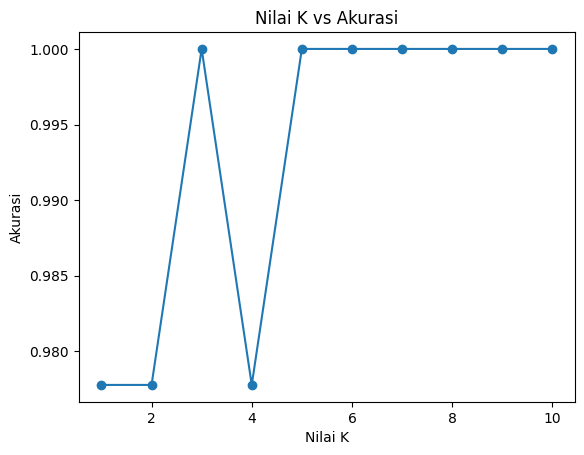

In [8]:
	acc = []
	for k in range(1, 11):
	    model = KNeighborsClassifier(n_neighbors=k)
	    model.fit(X_train, y_train)
	    acc.append(model.score(X_test, y_test))

	plt.plot(range(1, 11), acc, marker='o')
	plt.title('Nilai K vs Akurasi')
	plt.xlabel('Nilai K')
	plt.ylabel('Akurasi')
	plt.show()


# Praktikum 2

In [9]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[ 82  59]
 [145 199]
 [113 137]
 [ 97  92]
 [117 143]
 [ 75  44]
 [120 141]
 [ 94  89]
 [197 190]
 [ 54  33]
 [ 56  56]
 [173 197]
 [ 90  94]
 [ 98  93]
 [ 76  70]
 [158 162]
 [ 37  36]
 [  5  45]
 [141 143]
 [ 37  32]
 [216 121]
 [ 48  53]
 [ 18 141]
 [124  20]
 [ 25 189]
 [ 27 180]
 [141  86]
 [103 241]
 [ 76 138]
 [ 63 141]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [10]:
	import pandas as pd

	# Reshape label y menjadi 2D
	# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
	y_new = y.reshape(len(y), 1)

	# Gabungkan fitur X dan label y dalam data array
	data = np.concatenate((X, y_new), axis=1)

	# Definisikan nama kolom
	nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

	# Buat Data Frame
	df = pd.DataFrame(data, columns=nama_kolom)

	# Cek Data Frame
	df.head()

,Fitur 1,Fitur 2,Label
0,82,59,0
1,145,199,0
2,113,137,0
3,97,92,0
4,117,143,0


In [11]:
	# Definisikan nama label
	labels = {
	    1 : 'Kelas A',
	    0 : 'Kelas B'
	}

	# Copy Data Frame untuk menyimpan Data Frame baru
	# dengan label yang mudah untuk dibaca
	df_label = df.copy()

	# Ubah label dengan fungsi mapping dari Pandas
	# pada Data Frame df_label
	df_label['Label'] = df_label['Label'].map(labels)

	# Cek Data Frame df_label
	df_label.head()

,Fitur 1,Fitur 2,Label
0,82,59,Kelas B
1,145,199,Kelas B
2,113,137,Kelas B
3,97,92,Kelas B
4,117,143,Kelas B


/tmp/ipykernel_1355/1912510248.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_1355/1912510248.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


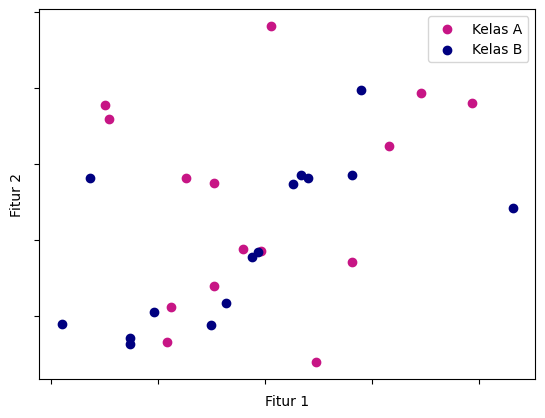

In [12]:
	import matplotlib.pyplot as plt

	# Definisikan warna untuk setiap kelas
	colors = {
	    'class_a': 'MediumVioletRed',
	    'class_b': 'Navy'
	}

	# Kelompokkan label berdasarkan nama kelas
	gb = df_label.groupby(['Label'])
	class_a = gb.get_group('Kelas A')
	class_b = gb.get_group('Kelas B')

	# Plot
	plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
	plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
	plt.xlabel('Fitur 1')
	plt.ylabel('Fitur 2')
	plt.legend(['Kelas A', 'Kelas B'])
	plt.gca().axes.xaxis.set_ticklabels([])
	plt.gca().axes.yaxis.set_ticklabels([])
	plt.show()

In [13]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.6666666666666666
Hasil akurasi data test: 0.5555555555555556


In [14]:
	from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

	# Inisiasi obyek Gaussian
	gnb = GaussianNB()

	# Kita menggunakan split data training dan testing
	# yang sama dengan model multinomial

	# Fit model
	# Label y harus dalam bentu 1D atau (n_samples,)
	gnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred_gnb = gnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

	# Prediksi test data
	y_test_pred_gnb = gnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
	print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.6190476190476191
Hasil akurasi data test (Gaussian): 0.2222222222222222


# Praktikum 3

In [15]:
	import numpy as np
	import pandas as pd

	df = pd.read_csv('spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

	df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [16]:
	# Drop 3 kolom terakhir dengan fungsi iloc
	df = df.drop(df.iloc[:,2:], axis=1)

	# Cek data
	df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [19]:
import numpy as np
import pandas as pd

# 1. Baca data
df = pd.read_csv('spam.csv', encoding='latin-1')

# 2. Hapus 3 kolom terakhir yang tidak digunakan
df = df.drop(df.iloc[:, 2:], axis=1)

# 3. Ganti nama kolom 'v1' menjadi 'label' dan 'v2' menjadi 'sms' (atau 'text')
df = df.rename(columns={'v1': 'label', 'v2': 'sms'})

# Cek 5 data teratas
print(df.head())
print('\n')

# Cek Jumlah Data Per Kelas
print(df['label'].value_counts())
print('\n')

# Cek Kelengkapan Data
print(df.info())
print('\n')

# Cek Statistik Deskriptif
print(df.describe())

  label                                                sms
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


label
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   sms     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       label                     sms
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30


In [21]:
# Pemetaan label kategorikal ke numerik
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label menggunakan map
df['label'] = df['label'].map(new_labels)

# Cek hasil encoding
df.head()

,label,sms
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [23]:
X = df['sms'].values
y = df['label'].values

In [24]:
	from sklearn.model_selection import train_test_split
	from sklearn.feature_extraction.text import CountVectorizer

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

	# Inisiasi CountVectorizer
	bow = CountVectorizer()

	# Fitting dan transform X_train dengan CountVectorizer
	X_train = bow.fit_transform(X_train)

	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
	X_test = bow.transform(X_test)

In [26]:
# Menghitung jumlah fitur (kosa kata) unik
print(len(bow.get_feature_names_out()))

# Menampilkan dimensi matriks data latih (jumlah sampel, jumlah fitur)
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


In [28]:
	from sklearn.naive_bayes import MultinomialNB
	from sklearn.metrics import accuracy_score

	# Inisiasi MultinomialNB
	mnb = MultinomialNB()

	# Fit model
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_pred_train = mnb.predict(X_train)

	# Evaluasi akurasi data training
	acc_train = accuracy_score(y_train, y_pred_train)

	# Prediksi dengan data training
	y_pred_test = mnb.predict(X_test)

	# Evaluasi akurasi data training
	acc_test = accuracy_score(y_test, y_pred_test)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


# Tugas 1

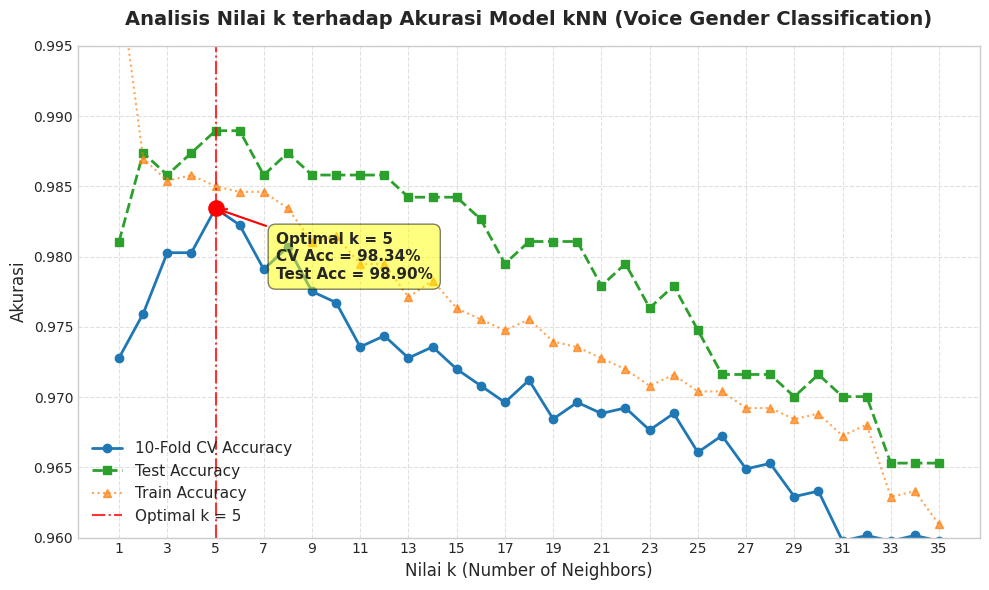

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# 1. Definisikan 9 fitur optimal
selected_feats_9 = ['meanfreq', 'sd', 'median', 'Q25', 'IQR', 'skew', 'sfm', 'meanfun', 'maxfun']

# 2. Buat scaler baru khusus untuk 9 fitur terpilih
scaler_9 = StandardScaler()
X_tr_s9 = scaler_9.fit_transform(X_train[selected_feats_9])
X_te_s9 = scaler_9.transform(X_test[selected_feats_9])

# 3. Iterasi pengujian nilai k dari 1 sampai 35
k_range = range(1, 36)
cv_scores_9 = []
train_scores_9 = []
test_scores_9 = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    # 10-Fold Cross-Validation pada data latih
    scores = cross_val_score(knn, X_tr_s9, y_train, cv=10)
    cv_scores_9.append(scores.mean())

    # Hitung akurasi pada data latih dan data uji
    knn.fit(X_tr_s9, y_train)
    train_scores_9.append(knn.score(X_tr_s9, y_train))
    test_scores_9.append(knn.score(X_te_s9, y_test))

# 4. Buat DataFrame df_k9
df_k9 = pd.DataFrame({
    'k': list(k_range),
    'Train_Acc': train_scores_9,
    'CV_Acc': cv_scores_9,
    'Test_Acc': test_scores_9
})

# 5. Visualisasi Hasil Penalaan Nilai k
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(df_k9['k'], df_k9['CV_Acc'], marker='o', color='#1f77b4', linewidth=2, label='10-Fold CV Accuracy')
ax1.plot(df_k9['k'], df_k9['Test_Acc'], marker='s', color='#2ca02c', linewidth=2, linestyle='--', label='Test Accuracy')
ax1.plot(df_k9['k'], df_k9['Train_Acc'], marker='^', color='#ff7f0e', linewidth=1.5, alpha=0.7, linestyle=':', label='Train Accuracy')

# Penanda titik k terbaik (k = 5)
best_k = 5
best_cv = df_k9.loc[df_k9['k'] == best_k, 'CV_Acc'].values[0]
best_test = df_k9.loc[df_k9['k'] == best_k, 'Test_Acc'].values[0]

ax1.axvline(x=best_k, color='red', linestyle='-.', alpha=0.8, label=f'Optimal k = {best_k}')
ax1.scatter([best_k], [best_cv], color='red', s=120, zorder=5)
ax1.annotate(f'Optimal k = {best_k}\nCV Acc = {best_cv*100:.2f}%\nTest Acc = {best_test*100:.2f}%',
             xy=(best_k, best_cv), xytext=(best_k + 2.5, best_cv - 0.005),
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
             fontsize=11, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.5))

ax1.set_title('Analisis Nilai k terhadap Akurasi Model kNN (Voice Gender Classification)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Nilai k (Number of Neighbors)', fontsize=12)
ax1.set_ylabel('Akurasi', fontsize=12)
ax1.set_xticks(range(1, 36, 2))
ax1.set_ylim(0.96, 0.995)
ax1.legend(loc='lower left', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Muat dataset
df = pd.read_csv('voice.csv')

# 2. Pisahkan fitur dan label
X = df.drop(columns=['label'])
y = df['label']

# 3. Encode label: female = 0, male = 1
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Split data (80% train, 20% test) secara stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 5. Standarisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Model kNN Baseline (Semua 20 Fitur, k=5)
knn_baseline = KNeighborsClassifier(n_neighbors=5)
knn_baseline.fit(X_train_scaled, y_train)

# Evaluasi baseline
y_pred_base = knn_baseline.predict(X_test_scaled)
cv_base = cross_val_score(knn_baseline, X_train_scaled, y_train, cv=10).mean()

print(f"Akurasi Baseline 10-Fold CV : {cv_base * 100:.2f}%")
print(f"Akurasi Baseline Data Uji   : {accuracy_score(y_test, y_pred_base) * 100:.2f}%")

Akurasi Baseline 10-Fold CV : 97.32%
Akurasi Baseline Data Uji   : 97.63%


# Tugas 2

In [34]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

# 1. Load Data spam.csv
df = pd.read_csv('spam.csv', encoding='latin-1')

# 2. Preprocessing Kolom dan Label
df = df.drop(df.iloc[:, 2:], axis=1)
df = df.rename(columns={'v1': 'label', 'v2': 'sms'})
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

X = df['sms']
y = df['label']

# 3. Split Dataset (80% Data Latih, 20% Data Uji)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==============================================================================
# TUGAS 2: Multinomial Naive Bayes dengan CountVectorizer (Stop Words Aktif)
# ==============================================================================
bow = CountVectorizer(stop_words='english')
X_train_bow = bow.fit_transform(X_train_raw)
X_test_bow = bow.transform(X_test_raw)

nb_bow = MultinomialNB()
nb_bow.fit(X_train_bow, y_train)
y_pred_bow = nb_bow.predict(X_test_bow)

acc_bow = accuracy_score(y_test, y_pred_bow)

print("=" * 60)
print("EVALUASI MODEL 1: CountVectorizer (dengan Stop Words)")
print("=" * 60)
print(f"Jumlah Fitur Kosa Kata : {len(bow.get_feature_names_out())}")
print(f"Akurasi                : {acc_bow * 100:.2f}%\n")
print("Classification Report:")
print(
    classification_report(
        y_test, y_pred_bow, target_names=['Ham (0)', 'Spam (1)'], digits=4
    )
)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_bow))

# ==============================================================================
# TUGAS 3: Multinomial Naive Bayes dengan TF-IDF (Stop Words Aktif)
# ==============================================================================
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_test_tfidf = tfidf.transform(X_test_raw)

nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_train_tfidf, y_train)
y_pred_tfidf = nb_tfidf.predict(X_test_tfidf)

acc_tfidf = accuracy_score(y_test, y_pred_tfidf)

print("\n" + "=" * 60)
print("EVALUASI MODEL 2: TF-IDF (dengan Stop Words)")
print("=" * 60)
print(f"Jumlah Fitur Kosa Kata : {len(tfidf.get_feature_names_out())}")
print(f"Akurasi                : {acc_tfidf * 100:.2f}%\n")
print("Classification Report:")
print(
    classification_report(
        y_test, y_pred_tfidf, target_names=['Ham (0)', 'Spam (1)'], digits=4
    )
)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tfidf))

# ==============================================================================
# PERBANDINGAN DAN KESIMPULAN
# ==============================================================================
df_comparison = pd.DataFrame(
    {
        'Metode Ekstraksi Fitur': [
            'CountVectorizer (Stop Words)',
            'TF-IDF (Stop Words)',
        ],
        'Jumlah Fitur': [
            len(bow.get_feature_names_out()),
            len(tfidf.get_feature_names_out()),
        ],
        'Akurasi Data Uji': [f'{acc_bow * 100:.2f}%', f'{acc_tfidf * 100:.2f}%'],
    }
)

print("\n" + "=" * 60)
print("TABEL PERBANDINGAN PERFORMA")
print("=" * 60)
print(df_comparison.to_string(index=False))

print("\nKESIMPULAN:")
if acc_bow > acc_tfidf:
  print(
      "- CountVectorizer memberikan performa akurasi yang lebih tinggi"
      f" ({acc_bow * 100:.2f}%) dibandingkan TF-IDF ({acc_tfidf * 100:.2f}%)."
  )
elif acc_tfidf > acc_bow:
  print(
      "- TF-IDF memberikan performa akurasi yang lebih tinggi"
      f" ({acc_tfidf * 100:.2f}%) dibandingkan CountVectorizer"
      f" ({acc_bow * 100:.2f}%)."
  )
else:
  print(
      "- Kedua metode menghasilkan akurasi yang seimbang pada data uji"
      f" ({acc_bow * 100:.2f}%)."
  )
print(
    "- Pada model Multinomial Naive Bayes untuk SMS spam, frekuensi kemunculan kata penting (CountVectorizer)"
)
print(
    "  sering kali memberikan sinyal klasifikasi yang lebih kuat dibanding pembobotan frekuensi dokumen (TF-IDF)."
)

EVALUASI MODEL 1: CountVectorizer (dengan Stop Words)
Jumlah Fitur Kosa Kata : 7440
Akurasi                : 98.39%

Classification Report:
              precision    recall  f1-score   support

     Ham (0)     0.9877    0.9938    0.9907       966
    Spam (1)     0.9580    0.9195    0.9384       149

    accuracy                         0.9839      1115
   macro avg     0.9728    0.9566    0.9645      1115
weighted avg     0.9837    0.9839    0.9837      1115

Confusion Matrix:
[[960   6]
 [ 12 137]]

EVALUASI MODEL 2: TF-IDF (dengan Stop Words)
Jumlah Fitur Kosa Kata : 7440
Akurasi                : 96.86%

Classification Report:
              precision    recall  f1-score   support

     Ham (0)     0.9650    1.0000    0.9822       966
    Spam (1)     1.0000    0.7651    0.8669       149

    accuracy                         0.9686      1115
   macro avg     0.9825    0.8826    0.9246      1115
weighted avg     0.9697    0.9686    0.9668      1115

Confusion Matrix:
[[966   0]
 [ 3